In [1]:
import logging
from collections import defaultdict
from collections.abc import Iterable, Mapping, Sequence
from functools import reduce
from itertools import product, zip_longest
from typing import Any

import colorcet as cc
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import wandb
from mpl_toolkits.axes_grid1 import make_axes_locatable


logger = logging.getLogger(__name__)


def reduce_fn(row, row_next):
    if row_next["loss_validation"] < row["loss_validation"]:
        return row_next
    else:
        return row


def get_sweep_results(
    entity: str,
    project: str,
    metric_names: list[str],
    hyperparam_names: list[str],
    config_filters: dict[str, Any] = dict(),
):
    api = wandb.Api()

    sweep_results = dict()
    for run in api.runs(
        f"{entity}/{project}",
        filters={"config." + k: v for k, v in config_filters.items()},
        lazy=False,
    ):
        logger.info("Fetching details for run: ", run.id, run.name)

        metrics_best = reduce(
            reduce_fn,
            run.scan_history(
                keys=["_step"] + [metric + "_validation" for metric in metric_names]
            ),
        )

        hyperparams = tuple(
            reduce(lambda d, k: d[k], hyper.split("."), run.config)
            for hyper in hyperparam_names
        )

        sweep_results[hyperparams] = metrics_best

    return sweep_results


def get_top_k(
    metrics: Sequence[tuple[Any, Mapping[str, float]]],
    sort_by: str,
    k: int | None = None,
    in_decreasing_order: bool = False,
):
    metrics_sorted = sorted(
        metrics, key=lambda x: x[1][sort_by], reverse=in_decreasing_order
    )
    return metrics_sorted[:k]


def get_grid_axes(hyperparams_list: Iterable[Sequence[Any]]) -> list[list[Any]]:
    # Use sets and for loops instead of np.unique and np.sort to handle non-numeric
    # types as well
    hparam_grids: dict[int, set[Any]] = defaultdict(set)
    for hparams in hyperparams_list:
        for i, val in enumerate(hparams):
            hparam_grids[i].add(val)
    return [sorted(list(hparam_grids[i])) for i in range(len(hparam_grids))]


def sweep_results_into_grid(
    sweep_results: Mapping[tuple[Any, ...], Mapping[str, float]],
) -> tuple[list[list[Any]], dict[str, np.ndarray]]:
    sweep_grids = defaultdict(list)
    hparam_axes = get_grid_axes(sweep_results.keys())
    for hparams in product(*hparam_axes):
        for k, v in sweep_results[hparams].items():
            sweep_grids[k].append(v)
    grid_shape = [len(g) for g in hparam_axes]
    sweep_grids = {k: np.asarray(v).reshape(grid_shape) for k, v in sweep_grids.items()}
    return hparam_axes, sweep_grids


In [2]:
def plot_sweep_results(
    sweep_results: Mapping[tuple[Any, ...], Mapping[str, float]],
    figsize: tuple[float, float],
    metric_names: list[str] | None = None,
    topk: list[tuple[tuple[Any, ...], Mapping[str, float]]] | None = None,
    *,
    wspace: float = 0.4,
):
    hparam_axes, metrics_grid = sweep_results_into_grid(sweep_results)
    metric_names = list(metrics_grid.keys()) if metric_names is None else metric_names
    if topk is not None:
        topk_locs = []
        for top_hparams, _ in topk:
            topk_locs.append(
                tuple(h_ax.index(h) for h_ax, h in zip(hparam_axes, top_hparams))
            )

    fig, axes = plt.subplots(
        1,
        len(metric_names),
        figsize=figsize,
        sharey=True,
        constrained_layout=True,
        gridspec_kw={"wspace": wspace},
    )
    for ax, name in zip(axes, metric_names):
        im = ax.imshow(
            metrics_grid[name],
            origin="lower",
            cmap=cc.m_coolwarm,
            norm=mcolors.LogNorm(),
        )
        if topk is not None:
            for xy0, c in zip_longest(topk_locs, ("#00FF00",), fillvalue="#FFFF00"):
                margin = 0.04
                rect = plt.Rectangle(
                    # y axis is the first hparam
                    (xy0[1] - 0.5 + margin, xy0[0] - 0.5 + margin),
                    1.0 - 2 * margin,
                    1.0 - 2 * margin,
                    facecolor="none",
                    edgecolor=c,
                    linewidth=1.2,
                )
                ax.add_patch(rect)
        ax.set_title(name, fontsize="medium")
        ax.set_xticks(np.arange(len(hparam_axes[1])), hparam_axes[1])
        ax.set_yticks(np.arange(len(hparam_axes[0])), hparam_axes[0])

        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="5%", pad=0.05)
        fig.colorbar(im, cax=cax, orientation="vertical")

    return fig


In [7]:
noise = 0.1
sweep_results = get_sweep_results(
    "jhko725",
    "lorenz63_revised",
    metric_names=["loss", "mmd_2", "mse"],
    hyperparam_names=["method.loss_fn.lambda_1", "method.loss_fn.lambda_2"],
    config_filters={
        "method.loss_fn._target_": "dynamics_discovery.loss_functions.DySLIMLoss",
        "model.key": 0,
        "data.noise_std_relative": noise,
        "training.optimizer.learning_rate": 0.001,
    },
)

top3 = get_top_k(
    get_top_k(sweep_results.items(), sort_by="mse_validation", k=3),
    sort_by="mmd_2_validation",
)
top3

[((1, 1),
  {'_step': 1624,
   'loss_validation': 0.0009250784059986472,
   'mmd_2_validation': 2.9629421987920068e-05,
   'mse_validation': 6.727103027515113e-05}),
 ((0, 1),
  {'_step': 1641,
   'loss_validation': 9.468568896409124e-05,
   'mmd_2_validation': 3.25096734741237e-05,
   'mse_validation': 6.217601185198873e-05}),
 ((0, 10),
  {'_step': 3745,
   'loss_validation': 0.0004755078407470137,
   'mmd_2_validation': 3.8664275052724406e-05,
   'mse_validation': 8.886508294381201e-05})]

Text(0.5, 0.98, 'Hyperparameter sweep results for DySLIM (Lorenz63): $\\sigma_{noise}=$0.1')

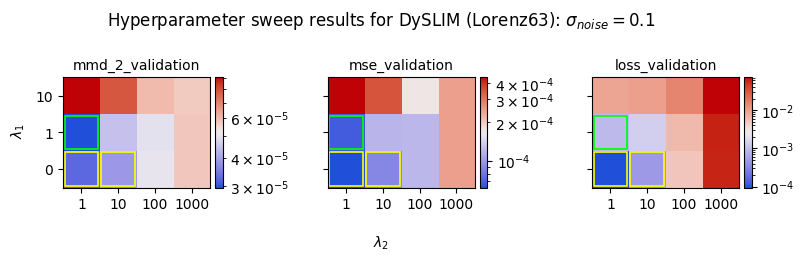

In [8]:
fig = plot_sweep_results(
    sweep_results,
    figsize=(7.5, 2.5),
    metric_names=["mmd_2_validation", "mse_validation", "loss_validation"],
    topk=top3,
)
fig.supylabel(r"$\lambda_1$", fontsize="medium")
fig.supxlabel(r"$\lambda_2$", fontsize="medium")
fig.suptitle(
    r"Hyperparameter sweep results for DySLIM (Lorenz63): $\sigma_{noise}=$"
    + f"{noise}"
)

## Efficient Neighborhood

In [5]:
noise = 0.1
sweep_results = get_sweep_results(
    "jhko725",
    "lorenz63_revised",
    metric_names=["loss", "loss_neighbors", "mse"],
    hyperparam_names=["method.loss_fn.weight", "method.loader_partial.num_neighbors"],
    config_filters={
        "method.name": "efficient_neighborhood",
        "model.key": 0,
        "data.noise_std_relative": noise,
        "training.optimizer.learning_rate": 0.001,
    },
)

top3 = get_top_k(
    get_top_k(sweep_results.items(), sort_by="mse_validation", k=3),
    sort_by="loss_neighbors_validation",
)
top3

[((10, 16),
  {'_step': 4284,
   'loss_validation': 0.006441888865083456,
   'loss_neighbors_validation': 0.0006416462128981948,
   'mse_validation': 2.5426295906072482e-05}),
 ((1000, 16),
  {'_step': 4284,
   'loss_validation': 0.6737261414527893,
   'loss_neighbors_validation': 0.0006736996583640575,
   'mse_validation': 2.6458998036105186e-05}),
 ((100, 16),
  {'_step': 4284,
   'loss_validation': 0.06755895167589188,
   'loss_neighbors_validation': 0.0006753245834261179,
   'mse_validation': 2.6491074095247313e-05})]

Text(0.5, 0.98, 'Hyperparameter sweep results for EfficientNeighborhood (Lorenz63): $\\sigma_{noise}=$0.1')

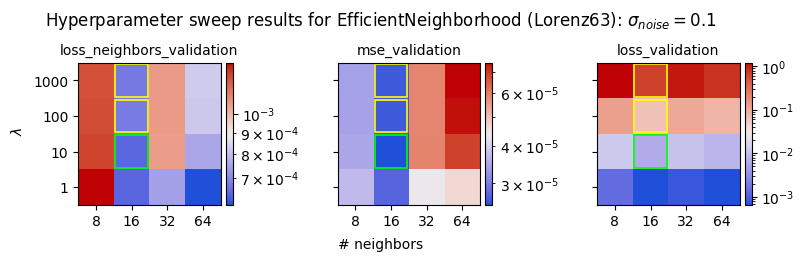

In [6]:
fig = plot_sweep_results(
    sweep_results,
    figsize=(7.5, 2.5),
    metric_names=["loss_neighbors_validation", "mse_validation", "loss_validation"],
    topk=top3,
)
fig.supylabel(r"$\lambda$", fontsize="medium")
fig.supxlabel("# neighbors", fontsize="medium")
fig.suptitle(
    r"""Hyperparameter sweep results for EfficientNeighborhood (Lorenz63): $\sigma_{noise}=$"""
    + f"{noise}"
)

# Lorenz 96

In [25]:
noise = 0.1
dim = 54
sweep_results = get_sweep_results(
    "jhko725",
    f"lorenz96_{dim}d_revised",
    metric_names=["loss", "mmd_2", "mse"],
    hyperparam_names=["method.loss_fn.lambda_1", "method.loss_fn.lambda_2"],
    config_filters={
        "method.loss_fn._target_": "dynamics_discovery.loss_functions.DySLIMLoss",
        "model.key": 0,
        "data.noise_std_relative": noise,
        "training.optimizer.learning_rate": 0.002,
    },
)

top3 = get_top_k(
    get_top_k(sweep_results.items(), sort_by="mse_validation", k=3),
    sort_by="mmd_2_validation",
)
top3

[((1, 100),
  {'_step': 16632,
   'loss_validation': 0.15887388586997986,
   'mmd_2_validation': 0.0015155143337324262,
   'mse_validation': 0.005595503840595484}),
 ((0, 100),
  {'_step': 16632,
   'loss_validation': 0.15771649777889252,
   'mmd_2_validation': 0.0015213037841022015,
   'mse_validation': 0.005586117971688509}),
 ((0, 10),
  {'_step': 16632,
   'loss_validation': 0.021016748622059822,
   'mmd_2_validation': 0.0015476059634238482,
   'mse_validation': 0.005540689919143915})]

Text(0.5, 0.98, 'Hyperparameter sweep results for DySLIM (Lorenz96 54D): $\\sigma_{noise}=$0.1')

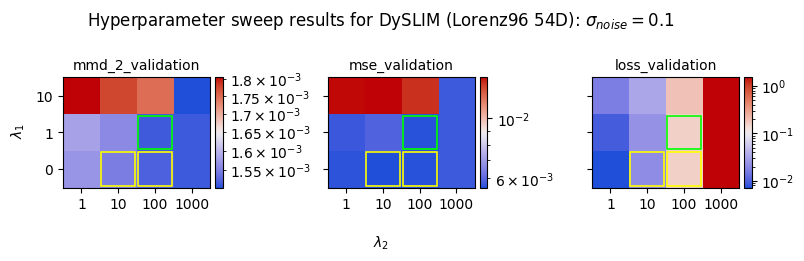

In [26]:
fig = plot_sweep_results(
    sweep_results,
    figsize=(7.5, 2.5),
    metric_names=["mmd_2_validation", "mse_validation", "loss_validation"],
    topk=top3,
)
fig.supylabel(r"$\lambda_1$", fontsize="medium")
fig.supxlabel(r"$\lambda_2$", fontsize="medium")
fig.suptitle(
    f"Hyperparameter sweep results for DySLIM (Lorenz96 {dim}D): "
    + r"$\sigma_{noise}=$"
    + f"{noise}"
)


In [ ]:
noise = 0.1
dim = 54
sweep_results = get_sweep_results(
    "jhko725",
    f"lorenz96_{dim}d_revised",
    metric_names=["loss", "loss_neighbors", "mse"],
    hyperparam_names=["method.loss_fn.weight", "method.loader_partial.num_neighbors"],
    config_filters={
        "method.name": "efficient_neighborhood",
        "model.key": 0,
        "data.noise_std_relative": noise,
        "training.optimizer.learning_rate": 0.002,
    },
)
top3 = get_top_k(
    get_top_k(sweep_results.items(), sort_by="mse_validation", k=3),
    sort_by="loss_neighbors_validation",
)
top3

[((1000, 32),
  {'_step': 18052,
   'loss_validation': 92.75140380859375,
   'loss_neighbors_validation': 0.09274627268314362,
   'mse_validation': 0.0051343245431780815}),
 ((100, 32),
  {'_step': 18052,
   'loss_validation': 9.313471794128418,
   'loss_neighbors_validation': 0.09308318793773651,
   'mse_validation': 0.005152661353349686}),
 ((1, 32),
  {'_step': 18052,
   'loss_validation': 0.10052014887332916,
   'loss_neighbors_validation': 0.09519009292125702,
   'mse_validation': 0.005330059677362442})]

Text(0.5, 0.98, 'Hyperparameter sweep results for EfficientNeighborhood (Lorenz96 54D): $\\sigma_{noise}=$0.1')

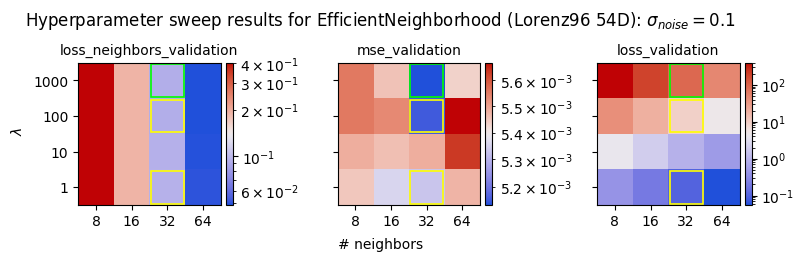

In [30]:
fig = plot_sweep_results(
    sweep_results,
    figsize=(7.5, 2.5),
    metric_names=["loss_neighbors_validation", "mse_validation", "loss_validation"],
    topk=top3,
)
fig.supylabel(r"$\lambda$", fontsize="medium")
fig.supxlabel("# neighbors", fontsize="medium")
fig.suptitle(
    f"Hyperparameter sweep results for EfficientNeighborhood (Lorenz96 {dim}D): "
    + r"$\sigma_{noise}=$"
    + f"{noise}"
)

In [ ]:
# Lorenz96 (18D)

In [3]:
sweep_results = get_sweep_results(
    "jhko725",
    "lorenz96_18d_revised",
    metric_names=["loss", "mmd_2", "mse"],
    hyperparam_names=["method.loss_fn.lambda_1", "method.loss_fn.lambda_2"],
    config_filters={
        "method.loss_fn._target_": "dynamics_discovery.loss_functions.DySLIMLoss",
        "model.key": 0,
        "data.noise_std_relative": 0.01,
    },
)

top3 = get_top_k(
    get_top_k(sweep_results.items(), sort_by="mmd_2_validation", k=3),
    sort_by="mse_validation",
)
top3

wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /home/jhko725/.netrc.


[((0, 1),
  {'_step': 4981,
   'loss_validation': 0.0002466167393847672,
   'mmd_2_validation': 8.523831174788289e-05,
   'mse_validation': 0.0001613784276368843}),
 ((0, 10),
  {'_step': 4914,
   'loss_validation': 0.0011362082729726463,
   'mmd_2_validation': 9.474207080622812e-05,
   'mse_validation': 0.00018878756491036517}),
 ((1, 10),
  {'_step': 4969,
   'loss_validation': 0.002538876903998708,
   'mmd_2_validation': 9.481349730685316e-05,
   'mse_validation': 0.0001892542413302014})]

Text(0.5, 0.98, 'Hyperparameter sweep results for DySLIM (Lorenz96 6D)')

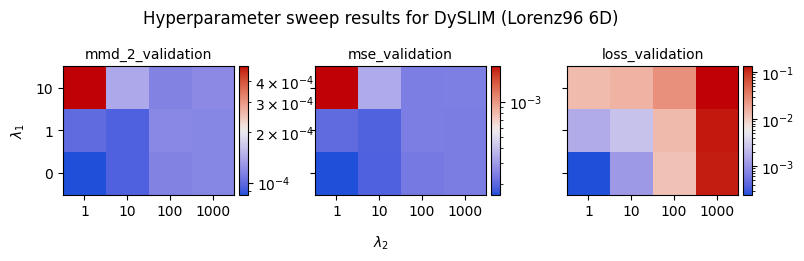

In [ ]:
fig = plot_sweep_results(
    sweep_results,
    figsize=(7.5, 2.5),
    metric_names=["mmd_2_validation", "mse_validation", "loss_validation"],
)
fig.supylabel(r"$\lambda_1$", fontsize="medium")
fig.supxlabel(r"$\lambda_2$", fontsize="medium")
fig.suptitle("Hyperparameter sweep results for DySLIM (Lorenz96 18D)")

In [5]:
sweep_results = get_sweep_results(
    "jhko725",
    "lorenz96_18d_revised",
    metric_names=["loss", "loss_neighbors", "mse"],
    hyperparam_names=["method.loss_fn.weight", "method.loader_partial.num_neighbors"],
    config_filters={
        "method.name": "efficient_neighborhood",
        "model.key": 0,
        "data.noise_std_relative": 0.01,
    },
)


In [6]:
top3 = get_top_k(
    get_top_k(sweep_results.items(), sort_by="mse_validation", k=3),
    sort_by="loss_neighbors_validation",
)
top3

[((1, 8),
  {'_step': 4981,
   'loss_validation': 0.01989045072195794,
   'loss_neighbors_validation': 0.019824054295511824,
   'mse_validation': 6.639642644611499e-05}),
 ((10, 8),
  {'_step': 4940,
   'loss_validation': 0.21219135102734168,
   'loss_neighbors_validation': 0.021211590371479464,
   'mse_validation': 7.54473125470566e-05}),
 ((100, 8),
  {'_step': 4940,
   'loss_validation': 2.142021255178433,
   'loss_neighbors_validation': 0.021419452242526366,
   'mse_validation': 7.60309257960765e-05})]

Text(0.5, 0.98, 'Hyperparameter sweep results for EfficientNeighborhood (Lorenz96 18D)')

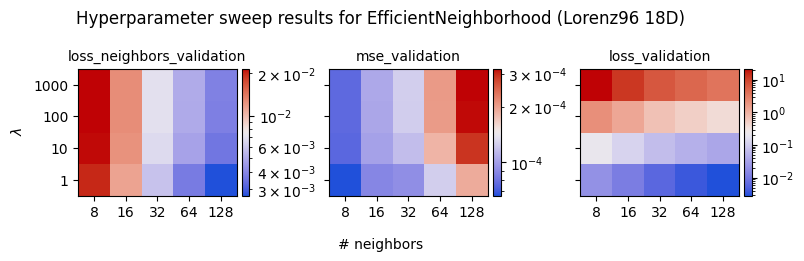

In [7]:
fig = plot_sweep_results(
    sweep_results,
    figsize=(7.5, 2.5),
    metric_names=["loss_neighbors_validation", "mse_validation", "loss_validation"],
    wspace=0.3,
)
fig.supylabel(r"$\lambda$", fontsize="medium")
fig.supxlabel("# neighbors", fontsize="medium")
fig.suptitle("Hyperparameter sweep results for EfficientNeighborhood (Lorenz96 18D)")